In [18]:
# Import Pandas for data manipulation and analysis
import pandas as pd

# Import NumPy for numerical calculations
import numpy as np

# Import Matplotlib and Seaborn for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent style for charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the Uber trip dataset
trips = pd.read_csv(r"C:\Users\M.SANTHOSH\Downloads\Uber Trip Details.csv")

# Load the location dataset
locations = pd.read_csv(r"C:\Users\M.SANTHOSH\Downloads\Location Table.csv")

# Create copies for analysis
trips_analysis = trips.copy()
locations_analysis = locations.copy()

# Display the first five records from both datasets
display(trips_analysis.head())
display(locations_analysis.head())

,Trip ID,Pickup Time,Drop Off Time,passenger_count,trip_distance,PULocationID,DOLocationID,fare_amount,Surge Fee,Vehicle,Payment_type
0,1,01-06-2024 0.42,01-06-2024 1.04,1,5.60,79,226,19.5,2.0,UberX,Uber Pay
1,2,01-06-2024 0.06,01-06-2024 0.13,1,1.72,142,186,8.0,0.0,Uber Black,Cash
2,3,01-06-2024 0.08,01-06-2024 0.21,1,3.41,229,238,13.0,0.0,Uber Black,Cash
3,4,01-06-2024 0.28,01-06-2024 0.37,1,1.81,188,35,9.0,0.0,UberX,Cash
4,5,01-06-2024 0.38,01-06-2024 0.45,1,1.89,100,137,8.0,0.0,Uber Black,Cash


,LocationID,Location,City
0,1,Newark Airport,"Newark, New Jersey"
1,2,Jamaica Bay,Queens
2,3,Allerton/Pelham Gardens,The Bronx
3,4,Alphabet City,Manhattan
4,5,Arden Heights,Staten Island


# Question 1: What is the total number of Uber trips?

**Why are we running this code?**

To understand the overall volume of trips recorded in the dataset and establish a baseline for business analysis.

In [19]:
# Count unique trip IDs to calculate the total number of trips
total_trips = trips_analysis["Trip ID"].nunique()

# Display the total number of trips
print("Total Number of Trips:", total_trips)

Total Number of Trips: 103728


# Question 2: What is the total fare revenue generated?

**Why are we running this code?**

To calculate the total fare amount collected across all recorded trips and understand the overall revenue generated.


In [20]:
# Calculate total fare revenue by adding all fare amounts
total_revenue = trips_analysis["fare_amount"].sum()

# Display the total fare revenue
print("Total Fare Revenue:", round(total_revenue, 2))

Total Fare Revenue: 1348291.45


# Question 3: What is the average fare per trip?

**Why are we running this code?**

To determine the average fare charged per trip and understand typical trip pricing.

In [21]:
# Calculate the average fare across all trips
average_fare = trips_analysis["fare_amount"].mean()

# Display the average fare rounded to two decimal places
print("Average Fare per Trip:", round(average_fare, 2))

Average Fare per Trip: 13.0


# Question 4: What is the average trip distance?

**Why are we running this code?**

To understand the typical distance travelled per trip and identify the average trip length in the dataset.

In [22]:
# Calculate the average distance travelled per trip
average_distance = trips_analysis["trip_distance"].mean()

# Display the average trip distance
print("Average Trip Distance:", round(average_distance, 2))

Average Trip Distance: 3.36


# Question 5: How many trips were completed by each vehicle type?

**Why are we running this code?**

To compare trip demand across vehicle types and identify which vehicles account for the highest number of trips.

Vehicle
UberX           38744
Uber Comfort    17078
Uber Black      16710
UberXL          16698
Uber Green      14498
Name: count, dtype: int64


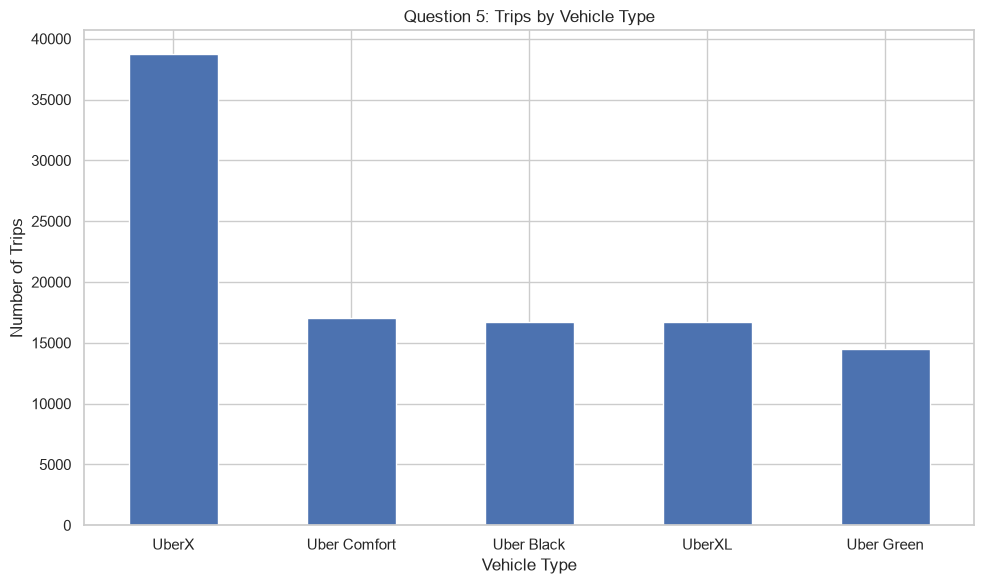

In [23]:
# Count trips for each vehicle type
vehicle_counts = trips_analysis["Vehicle"].value_counts()

# Display the trip counts by vehicle type
print(vehicle_counts)

# Create a bar chart to compare trip counts across vehicle types
vehicle_counts.plot(kind="bar", rot=0)
plt.title("Question 5: Trips by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

# Question 6: What is the distribution of payment methods?

**Why are we running this code?**

To understand which payment methods customers use most frequently and compare their share of total trips.

Payment_type
Uber Pay      69530
Cash          33434
Amazon Pay      584
Google Pay      180
Name: count, dtype: int64


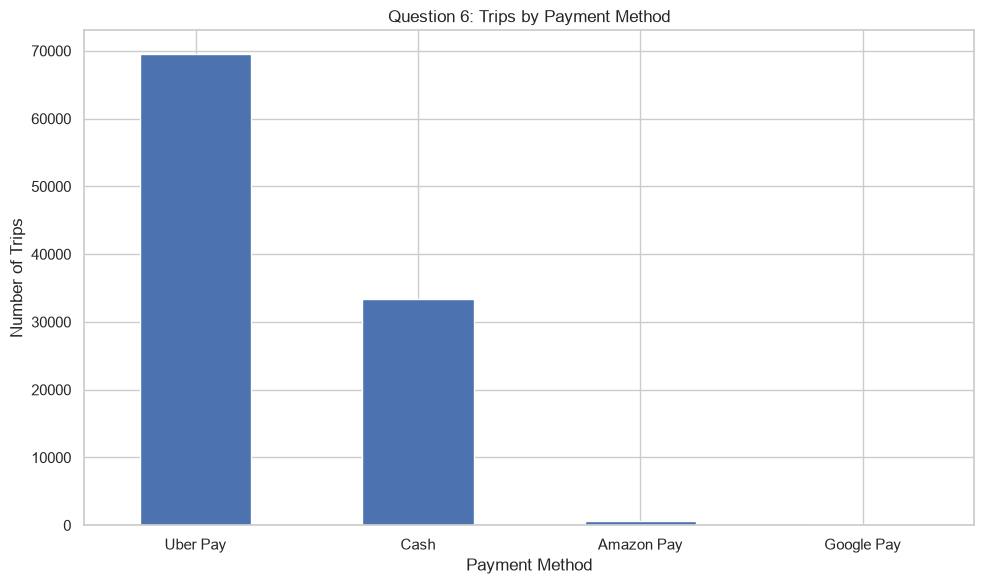

In [24]:
# Count trips for each payment method
payment_counts = trips_analysis["Payment_type"].value_counts()

# Display the trip counts by payment method
print(payment_counts)

# Create a bar chart to compare payment methods
payment_counts.plot(kind="bar", rot=0)
plt.title("Question 6: Trips by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

# Question 7: Which are the top 10 pickup locations?

**Why are we running this code?**

To identify the most frequently used pickup locations and understand where trip demand is concentrated.

Location
Penn Station/Madison Sq West    4475
Upper East Side North           4459
Upper East Side South           4124
Lenox Hill East                 3955
Upper West Side North           3752
Clinton East                    3722
Lenox Hill West                 3617
Lincoln Square East             3519
Yorkville West                  3393
Murray Hill                     3305
Name: Trip ID, dtype: int64


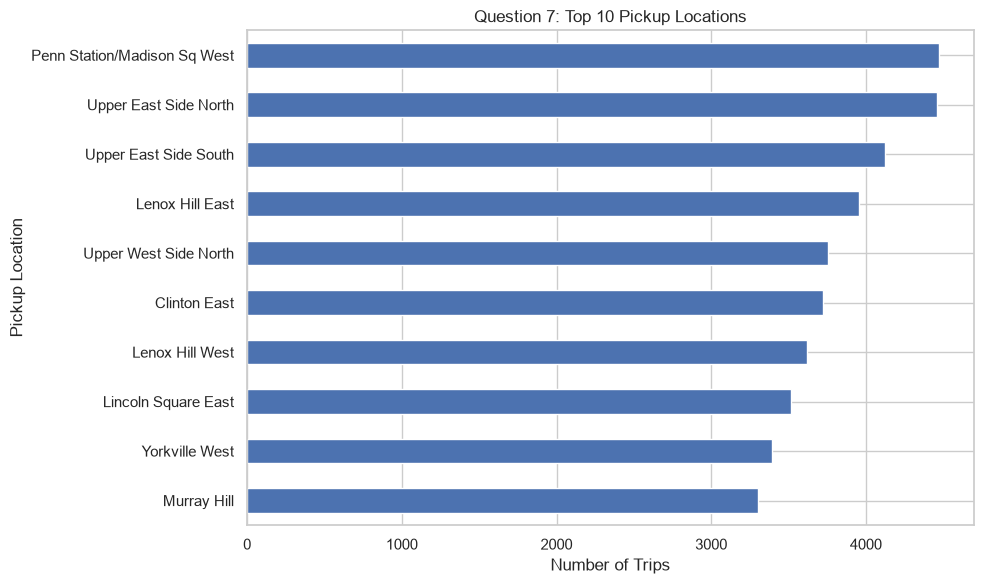

In [25]:
# Join trip records with the location dataset to identify pickup location names
pickup_analysis = trips_analysis.merge(
    locations_analysis[["LocationID", "Location"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
)

# Count trips for each pickup location and select the top 10
top_pickup_locations = (
    pickup_analysis.groupby("Location")["Trip ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 pickup locations
print(top_pickup_locations)

# Create a bar chart of the busiest pickup locations
top_pickup_locations.sort_values().plot(kind="barh")
plt.title("Question 7: Top 10 Pickup Locations")
plt.xlabel("Number of Trips")
plt.ylabel("Pickup Location")
plt.tight_layout()
plt.show()

# Question 8: Which are the top 10 drop-off locations?

**Why are we running this code?**

To identify the most popular drop-off locations and understand where passengers most frequently end their trips.

Location
Upper East Side North    4024
East Harlem South        3512
Upper East Side South    3357
Lenox Hill East          3194
Murray Hill              2906
Lenox Hill West          2881
Upper West Side North    2841
Clinton East             2800
East Harlem North        2732
Yorkville West           2724
Name: Trip ID, dtype: int64


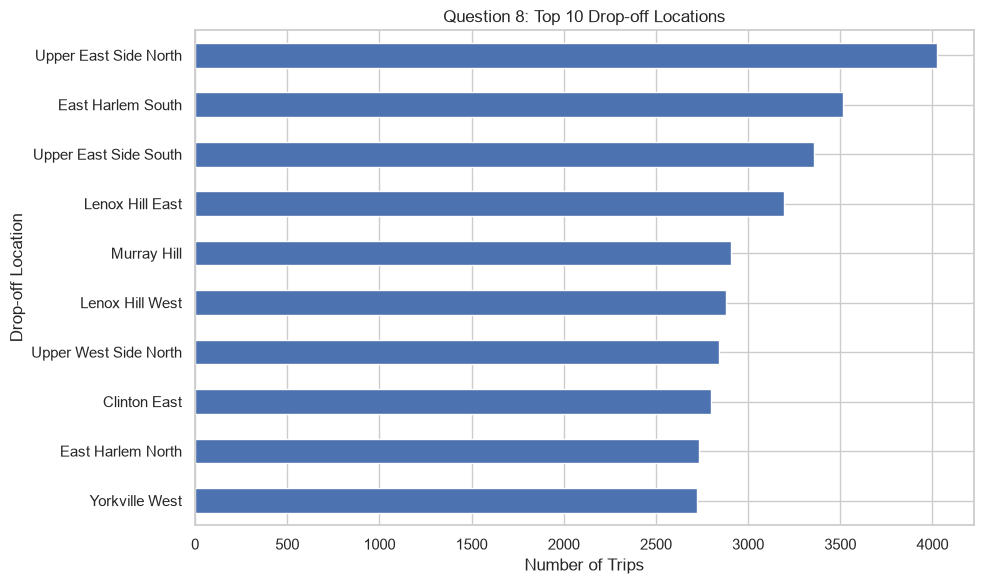

In [26]:
# Join trip records with the location dataset to identify drop-off location names
dropoff_analysis = trips_analysis.merge(
    locations_analysis[["LocationID", "Location"]],
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
)

# Count trips for each drop-off location and select the top 10
top_dropoff_locations = (
    dropoff_analysis.groupby("Location")["Trip ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 drop-off locations
print(top_dropoff_locations)

# Create a bar chart of the busiest drop-off locations
top_dropoff_locations.sort_values().plot(kind="barh")
plt.title("Question 8: Top 10 Drop-off Locations")
plt.xlabel("Number of Trips")
plt.ylabel("Drop-off Location")
plt.tight_layout()
plt.show()

# Question 9: Which vehicle types generate the highest total fare revenue?

**Why are we running this code?**

To compare total fare revenue across vehicle types and identify which vehicle categories contribute the most fare revenue.

Vehicle
UberX           507140.77
Uber Comfort    220584.98
Uber Black      217094.00
UberXL          216026.50
Uber Green      187445.20
Name: fare_amount, dtype: float64


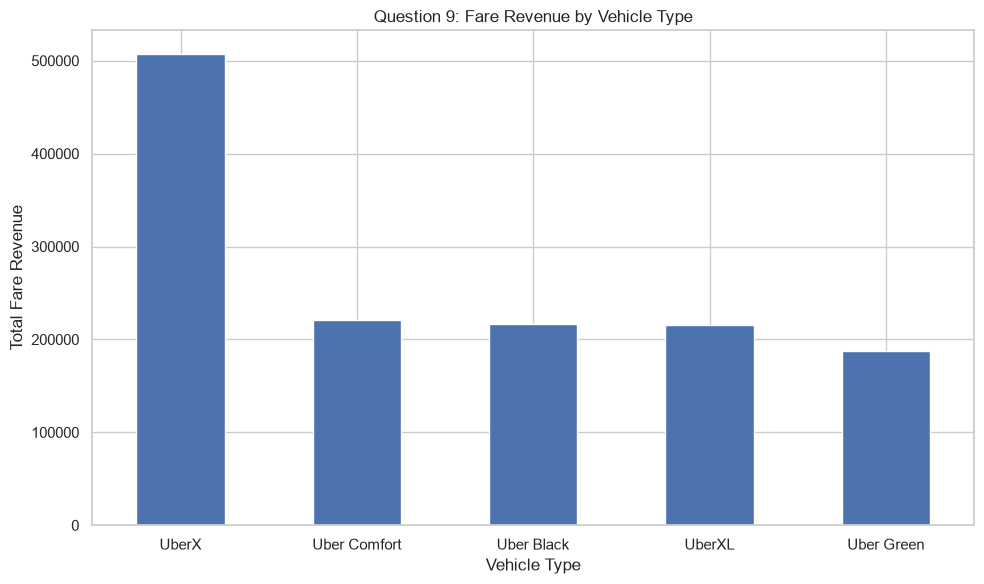

In [27]:
# Group trips by vehicle type and calculate total fare revenue
revenue_by_vehicle = (
    trips_analysis.groupby("Vehicle")["fare_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Display total fare revenue by vehicle type
print(revenue_by_vehicle.round(2))

# Create a bar chart to compare fare revenue by vehicle
revenue_by_vehicle.plot(kind="bar", rot=0)
plt.title("Question 9: Fare Revenue by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Total Fare Revenue")
plt.tight_layout()
plt.show()

# Question 10: What is the total surge fee collected by each vehicle type?

**Why are we running this code?**

To compare the total surge fees recorded for each vehicle type and understand how surge charges are distributed across the fleet.

Vehicle
UberX           76738.87
Uber Comfort    33410.51
UberXL          33397.93
Uber Black      33098.46
Uber Green      28735.59
Name: Surge Fee, dtype: float64


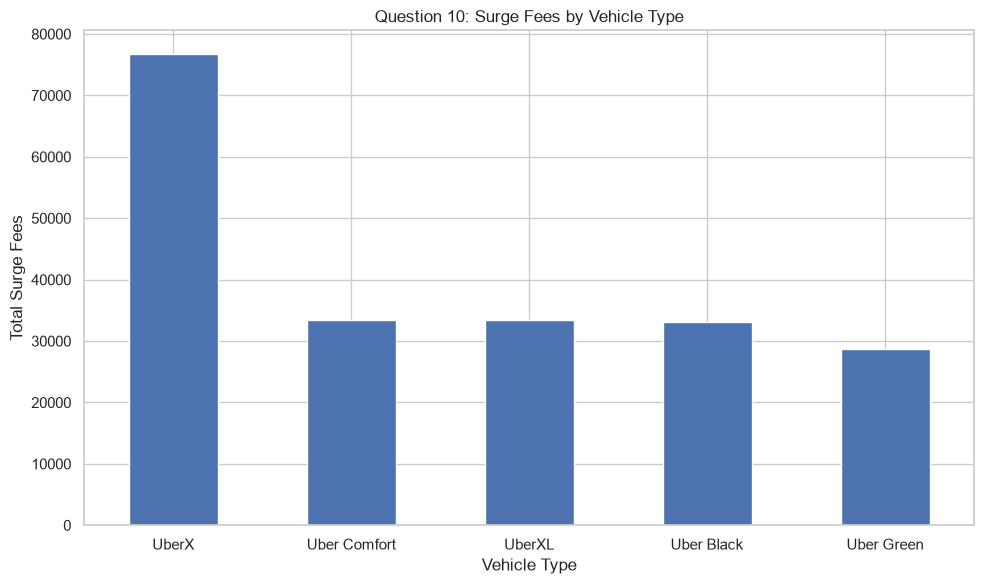

In [28]:
# Group trips by vehicle type and calculate the total surge fee
surge_by_vehicle = (
    trips_analysis.groupby("Vehicle")["Surge Fee"]
    .sum()
    .sort_values(ascending=False)
)

# Display total surge fees by vehicle type
print(surge_by_vehicle.round(2))

# Create a bar chart to compare surge fees across vehicle types
surge_by_vehicle.plot(kind="bar", rot=0)
plt.title("Question 10: Surge Fees by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Total Surge Fees")
plt.tight_layout()
plt.show()